# 🌫️ Mumbai Air Quality Index — Predictive Modelling
**Course:** Machine Learning and Big Data Applications in Sustainability (STEM)  
**Faculty:** Mr. Ashish Raj  
**Semester:** 8 | BS in Analytics and Sustainability Studies  
**Institute:** Tata Institute of Social Sciences (TISS)

---
## Dataset Overview
The dataset contains **1,095 daily observations** (2021–2023) for Mumbai with the following features:

| Feature | Description |
|---|---|
| `PM2.5` | Fine particulate matter (µg/m³) |
| `PM10` | Coarse particulate matter (µg/m³) |
| `NO2` | Nitrogen dioxide (µg/m³) |
| `SO2` | Sulfur dioxide (µg/m³) |
| `CO` | Carbon monoxide (mg/m³) |
| `O3` | Ozone (µg/m³) |
| `Temperature` | °C |
| `Humidity` | % |
| `Wind_Speed` | km/h |
| `AQI` | Air Quality Index (target) |

---


## 0. Setup & Imports

In [1]:
# Install / import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (
    r2_score, mean_squared_error,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.decomposition import PCA

# Plot style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
print("✅ All libraries loaded successfully!")


✅ All libraries loaded successfully!


---
## 1. Load Dataset

> **If running on Google Colab**, upload `mumbai_aqi.csv` when prompted (or mount Google Drive).


In [2]:
# ── Option A: Upload file (Colab) ──
# from google.colab import files
# uploaded = files.upload()
# df = pd.read_csv(list(uploaded.keys())[0])

# ── Option B: Read from current directory ──
df = pd.read_csv('../data/mumbai_aqi.csv', parse_dates=['Date'])

print(f"Dataset shape: {df.shape}")
print(f"Date range  : {df['Date'].min().date()} → {df['Date'].max().date()}")
df.head(10)


Dataset shape: (1095, 11)
Date range  : 2021-01-01 → 2023-12-31


,Date,PM2.5,PM10,NO2,SO2,CO,O3,Temperature,Humidity,Wind_Speed,AQI
0,2021-01-01,347.379309,588.123328,96.379904,61.364315,4.334603,50.303923,19.999211,45.140940,9.914237,245
1,2021-01-02,319.443114,545.412350,137.798456,46.781040,4.353694,28.378390,18.000000,31.781180,3.114224,210
2,2021-01-03,355.405664,544.243608,169.239419,47.807955,3.855007,30.261177,24.485498,NaN,3.437340,235
3,2021-01-04,395.347356,699.580335,101.673524,44.552930,4.380482,24.637436,19.230550,40.034293,8.736729,271
4,2021-01-05,316.781939,548.923951,132.900404,47.338201,3.903343,43.545288,20.460507,39.771948,NaN,252
5,2021-01-06,317.246853,569.259953,116.021362,NaN,4.030779,53.813645,22.430252,46.142516,5.634485,234
6,2021-01-07,399.267977,591.867899,137.918877,29.857984,3.866673,35.646903,18.878831,30.000000,10.046884,262
7,2021-01-08,363.114431,679.945773,129.909578,60.026372,3.423356,31.182626,18.060005,42.926304,7.562378,261
8,2021-01-09,307.785961,519.048445,116.807698,52.559162,4.374450,30.586420,20.565485,37.996413,7.157372,197
9,2021-01-10,353.615825,634.392387,139.490987,40.237243,4.641587,5.000000,18.000000,33.680150,9.339486,245


In [3]:
# Basic info
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         1095 non-null   datetime64[us]
 1   PM2.5        1041 non-null   float64       
 2   PM10         1041 non-null   float64       
 3   NO2          1041 non-null   float64       
 4   SO2          1041 non-null   float64       
 5   CO           1041 non-null   float64       
 6   O3           1041 non-null   float64       
 7   Temperature  1041 non-null   float64       
 8   Humidity     1041 non-null   float64       
 9   Wind_Speed   1041 non-null   float64       
 10  AQI          1095 non-null   int64         
dtypes: datetime64[us](1), float64(9), int64(1)
memory usage: 94.2 KB


In [4]:
# Statistical summary
df.describe().round(2)


,Date,PM2.5,PM10,NO2,SO2,CO,O3,Temperature,Humidity,Wind_Speed,AQI
count,1095,1041.00,1041.00,1041.00,1041.00,1041.00,1041.00,1041.00,1041.00,1041.00,1095.00
mean,2022-07-02 00:00:00,183.09,314.13,80.57,29.83,2.50,49.72,27.93,65.20,6.91,130.33
min,2021-01-01 00:00:00,10.00,15.00,5.00,2.00,0.20,5.00,18.00,30.00,0.50,20.00
25%,2021-10-01 12:00:00,82.10,141.60,48.14,16.25,1.28,35.68,22.86,48.34,5.05,61.00
50%,2022-07-02 00:00:00,185.89,314.65,78.79,29.53,2.54,50.19,27.74,66.00,6.91,130.00
75%,2023-04-01 12:00:00,281.92,480.98,113.97,43.26,3.70,62.83,33.38,81.67,8.84,194.00
max,2023-12-31 00:00:00,446.24,754.49,197.13,71.67,5.80,103.89,38.00,98.00,14.59,292.00
std,NaN,111.34,190.94,40.50,16.33,1.38,18.82,5.92,19.12,2.80,73.47


---
## 2. Exploratory Data Analysis (EDA)


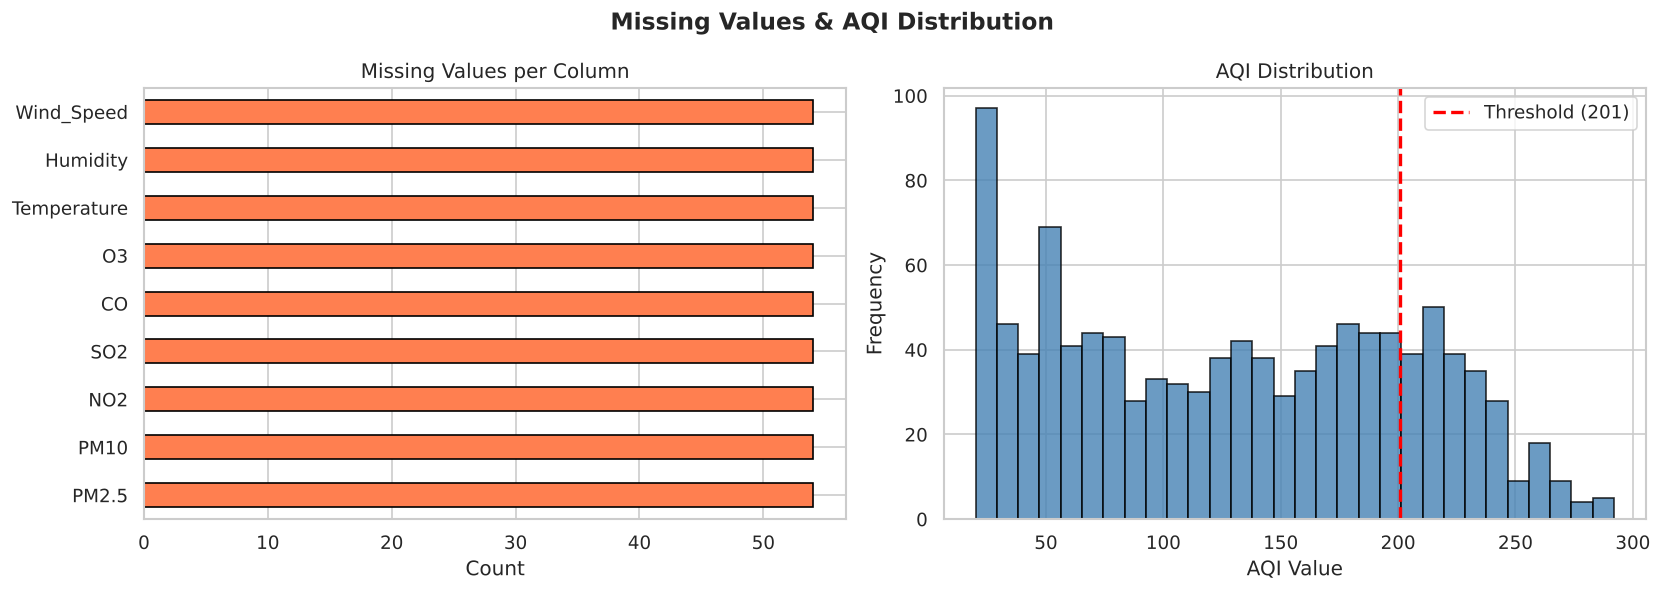


Missing values:
PM2.5          54
PM10           54
NO2            54
SO2            54
CO             54
O3             54
Temperature    54
Humidity       54
Wind_Speed     54
dtype: int64


In [5]:
# Missing value heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Missing counts
missing = df.isnull().sum()
missing[missing > 0].sort_values().plot(kind='barh', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Missing Values per Column')
axes[0].set_xlabel('Count')

# AQI distribution
axes[1].hist(df['AQI'], bins=30, color='steelblue', edgecolor='black', alpha=0.8)
axes[1].axvline(201, color='red', linestyle='--', linewidth=2, label='Threshold (201)')
axes[1].set_title('AQI Distribution')
axes[1].set_xlabel('AQI Value')
axes[1].set_ylabel('Frequency')
axes[1].legend()

plt.suptitle('Missing Values & AQI Distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print(f"\nMissing values:\n{missing[missing>0]}")


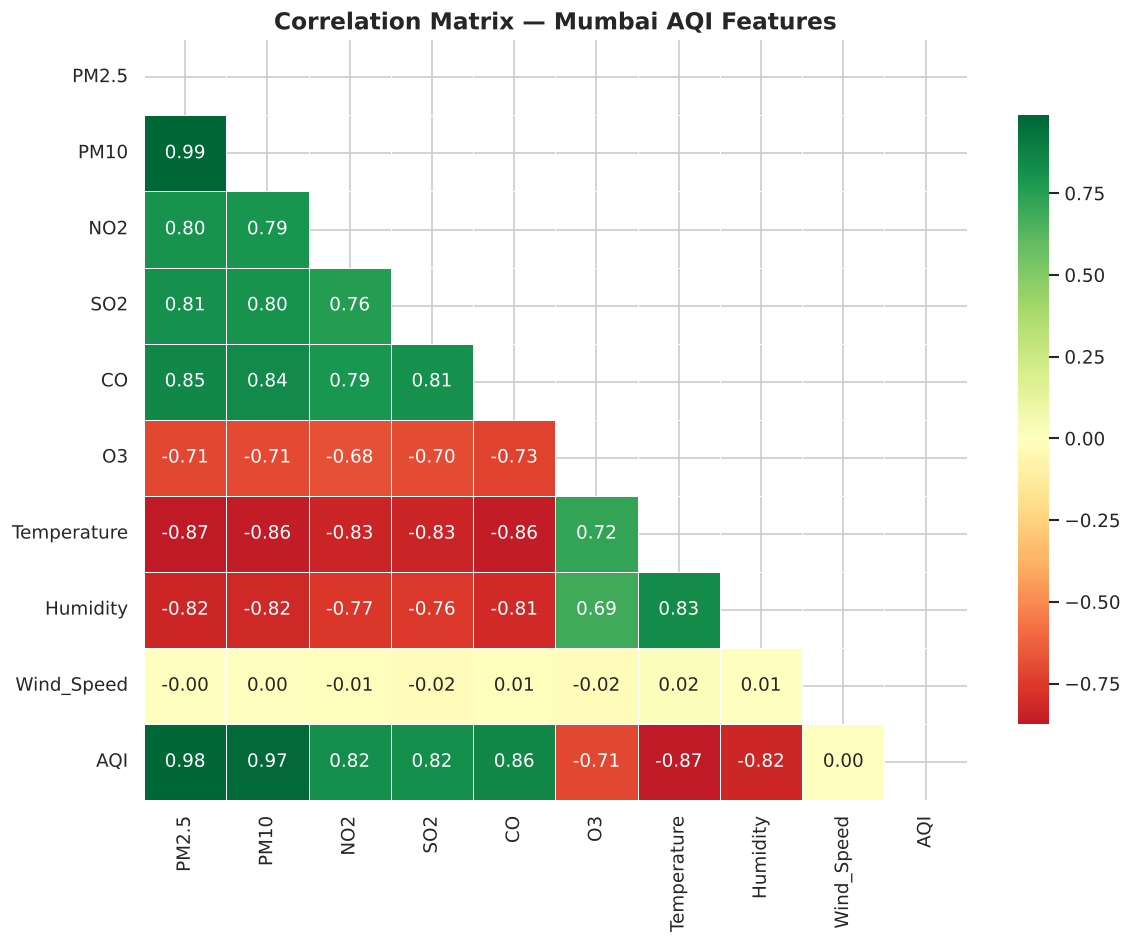

In [6]:
# Correlation heatmap (after dropping Date)
numeric_df = df.drop(columns=['Date']).dropna()
corr = numeric_df.corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix — Mumbai AQI Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


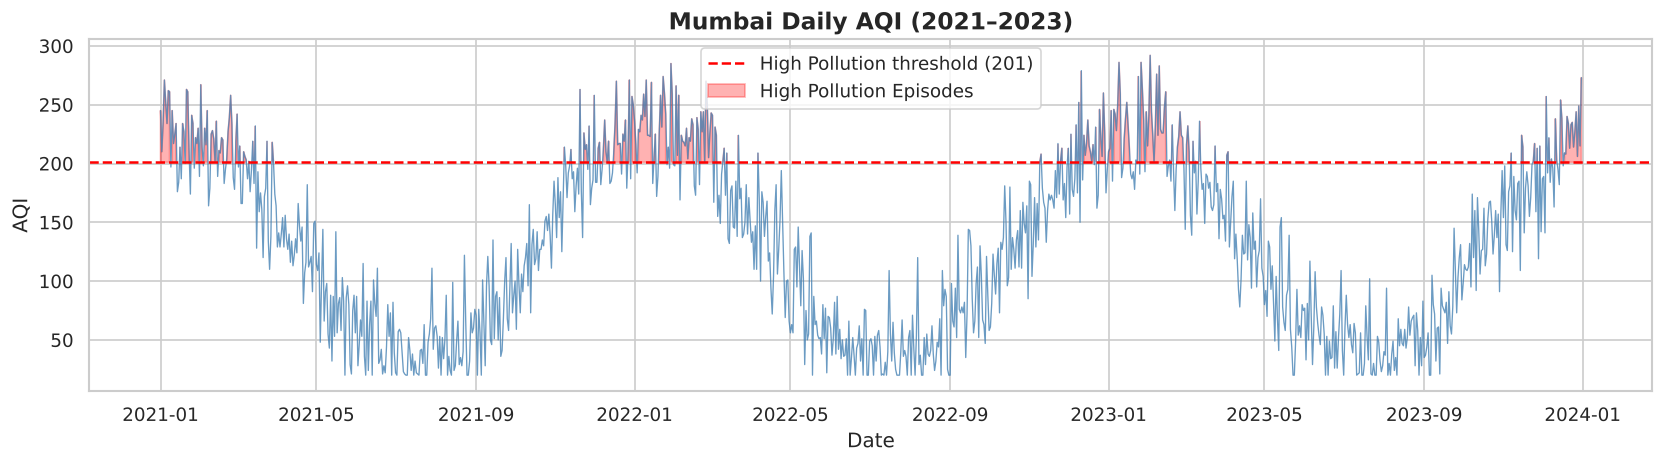

In [7]:
# AQI over time
plt.figure(figsize=(14, 4))
plt.plot(df['Date'], df['AQI'], color='steelblue', linewidth=0.8, alpha=0.8)
plt.axhline(201, color='red', linestyle='--', linewidth=1.5, label='High Pollution threshold (201)')
plt.fill_between(df['Date'], df['AQI'], 201,
                 where=(df['AQI'] >= 201), color='red', alpha=0.3, label='High Pollution Episodes')
plt.title('Mumbai Daily AQI (2021–2023)', fontsize=14, fontweight='bold')
plt.xlabel('Date'); plt.ylabel('AQI')
plt.legend(); plt.tight_layout(); plt.show()


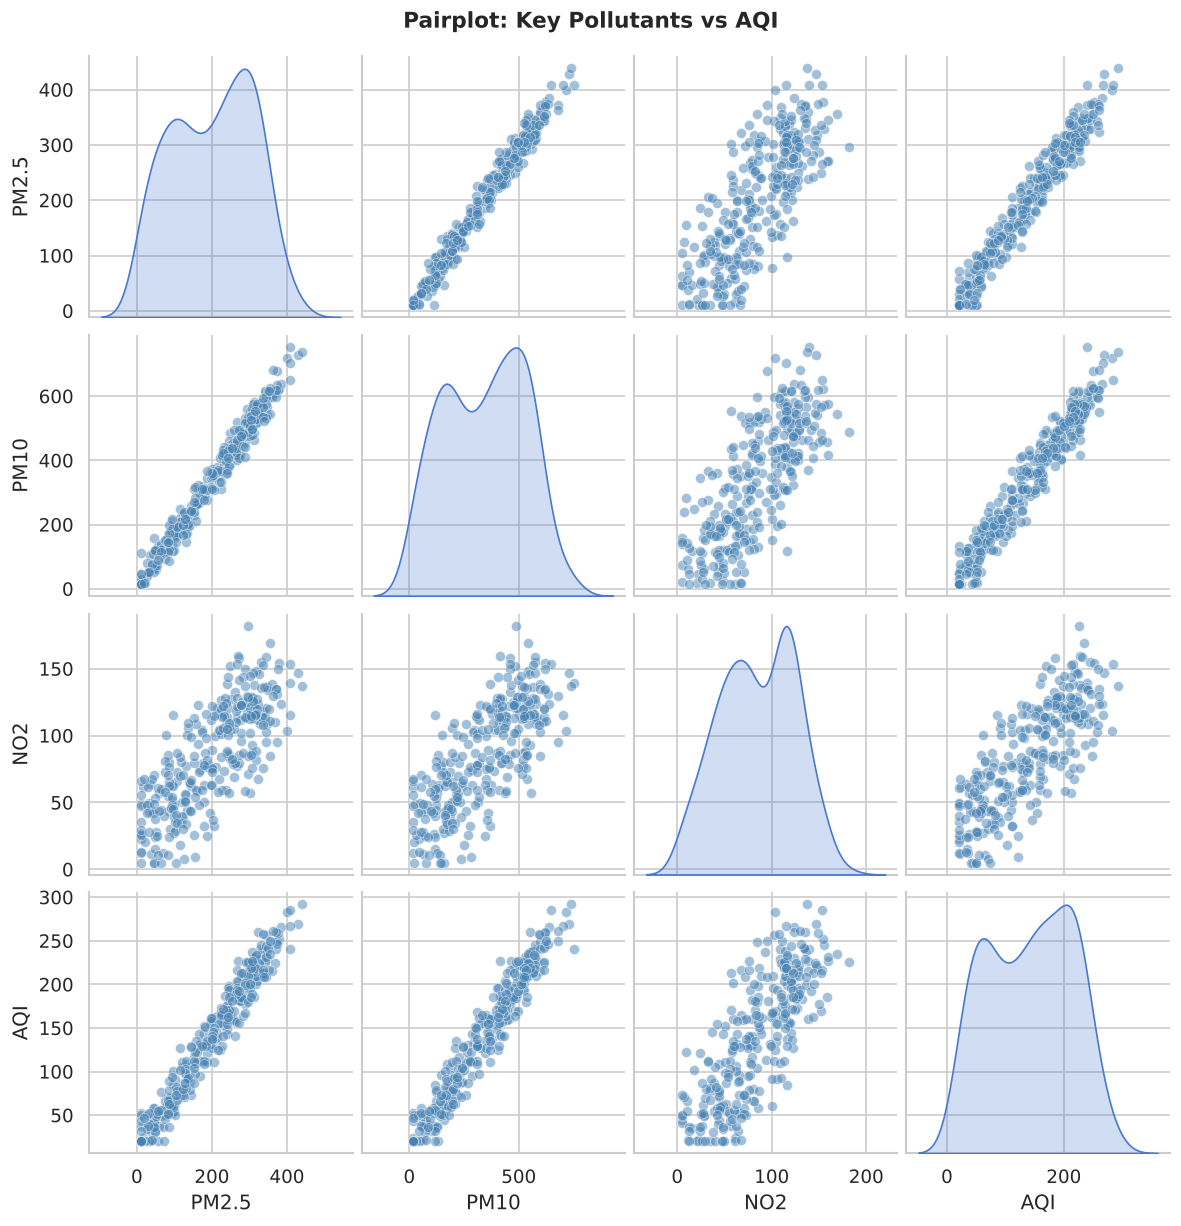

In [8]:
# Pairplot of top features vs AQI
top_features = ['PM2.5', 'PM10', 'NO2', 'AQI']
sample = df[top_features].dropna().sample(300, random_state=42)
sns.pairplot(sample, diag_kind='kde', plot_kws={'alpha': 0.5, 'color': 'steelblue'})
plt.suptitle('Pairplot: Key Pollutants vs AQI', y=1.02, fontsize=13, fontweight='bold')
plt.show()


---
## 3. Data Preprocessing

### Steps:
1. Handle missing values (median imputation)
2. Feature engineering — lag features & rolling averages
3. Feature selection based on correlation
4. Train-test split (80/20)


In [9]:
# ── 3.1 Median imputation for missing values ──
feature_cols = ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'Temperature', 'Humidity', 'Wind_Speed']
df_clean = df.copy()

for col in feature_cols:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)

print("Missing values after imputation:")
print(df_clean[feature_cols].isnull().sum())


Missing values after imputation:
PM2.5          0
PM10           0
NO2            0
SO2            0
CO             0
O3             0
Temperature    0
Humidity       0
Wind_Speed     0
dtype: int64


In [10]:
# ── 3.2 Feature engineering: lag and rolling features ──
df_clean = df_clean.sort_values('Date').reset_index(drop=True)

df_clean['AQI_lag1']    = df_clean['AQI'].shift(1)
df_clean['AQI_lag2']    = df_clean['AQI'].shift(2)
df_clean['AQI_roll3']   = df_clean['AQI'].shift(1).rolling(3).mean()
df_clean['PM25_roll7']  = df_clean['PM2.5'].shift(1).rolling(7).mean()

# Drop rows with NaN from lag/rolling
df_clean.dropna(inplace=True)
df_clean.reset_index(drop=True, inplace=True)

print(f"Shape after feature engineering: {df_clean.shape}")
df_clean[['Date','AQI','AQI_lag1','AQI_lag2','AQI_roll3','PM25_roll7']].head(8)


Shape after feature engineering: (1088, 15)


,Date,AQI,AQI_lag1,AQI_lag2,AQI_roll3,PM25_roll7
0,2021-01-08,261,262.0,234.0,249.333333,350.124602
1,2021-01-09,197,261.0,262.0,252.333333,352.372476
2,2021-01-10,245,197.0,261.0,240.000000,350.707169
3,2021-01-11,217,245.0,197.0,234.333333,350.451477
4,2021-01-12,225,217.0,245.0,219.666667,338.057702
5,2021-01-13,234,225.0,217.0,229.000000,336.901240
6,2021-01-14,176,234.0,225.0,225.333333,340.250022
7,2021-01-15,184,176.0,234.0,211.666667,318.042240


In [11]:
# ── 3.3 Feature selection for regression ──
all_features = ['PM2.5','PM10','NO2','SO2','CO','O3',
                'Temperature','Humidity','Wind_Speed',
                'AQI_lag1','AQI_lag2','AQI_roll3','PM25_roll7']

# Correlation with AQI
corr_with_aqi = df_clean[all_features + ['AQI']].corr()['AQI'].drop('AQI').abs().sort_values(ascending=False)
print("Feature correlations with AQI:")
print(corr_with_aqi.round(3))

# Select features with |r| > 0.2
selected_features = corr_with_aqi[corr_with_aqi > 0.2].index.tolist()
print(f"\nSelected features (|r| > 0.2): {selected_features}")


Feature correlations with AQI:
PM2.5          0.949
PM10           0.946
PM25_roll7     0.910
AQI_roll3      0.902
AQI_lag1       0.865
AQI_lag2       0.856
Temperature    0.854
CO             0.839
NO2            0.803
SO2            0.802
Humidity       0.798
O3             0.671
Wind_Speed     0.018
Name: AQI, dtype: float64

Selected features (|r| > 0.2): ['PM2.5', 'PM10', 'PM25_roll7', 'AQI_roll3', 'AQI_lag1', 'AQI_lag2', 'Temperature', 'CO', 'NO2', 'SO2', 'Humidity', 'O3']


In [12]:
# ── 3.4 Train-test split ──
X = df_clean[selected_features]
y = df_clean['AQI']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=False  # time-ordered
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f"Training set : {X_train.shape[0]} samples")
print(f"Test set     : {X_test.shape[0]} samples")
print(f"Features     : {list(X.columns)}")


Training set : 870 samples
Test set     : 218 samples
Features     : ['PM2.5', 'PM10', 'PM25_roll7', 'AQI_roll3', 'AQI_lag1', 'AQI_lag2', 'Temperature', 'CO', 'NO2', 'SO2', 'Humidity', 'O3']


---
## 4. Regression Analysis — Predicting AQI

### 4.1 Simple Linear Regression (PM2.5 → AQI)


In [13]:
# Simple Linear Regression
slr = LinearRegression()
slr.fit(X_train[['PM2.5']], y_train)
y_pred_slr = slr.predict(X_test[['PM2.5']])

r2_slr  = r2_score(y_test, y_pred_slr)
mse_slr = mean_squared_error(y_test, y_pred_slr)

print("=" * 45)
print("   SIMPLE LINEAR REGRESSION (PM2.5 → AQI)")
print("=" * 45)
print(f"  Intercept      : {slr.intercept_:.4f}")
print(f"  Coefficient    : {slr.coef_[0]:.4f}")
print(f"  R²             : {r2_slr:.4f}")
print(f"  MSE            : {mse_slr:.4f}")
print(f"  RMSE           : {np.sqrt(mse_slr):.4f}")
print("=" * 45)
print("\n📌 Interpretation:")
print(f"  For every 1 µg/m³ increase in PM2.5,")
print(f"  AQI increases by {slr.coef_[0]:.2f} units.")


   SIMPLE LINEAR REGRESSION (PM2.5 → AQI)
  Intercept      : 13.3256
  Coefficient    : 0.6434
  R²             : 0.8729
  MSE            : 595.8862
  RMSE           : 24.4108

📌 Interpretation:
  For every 1 µg/m³ increase in PM2.5,
  AQI increases by 0.64 units.


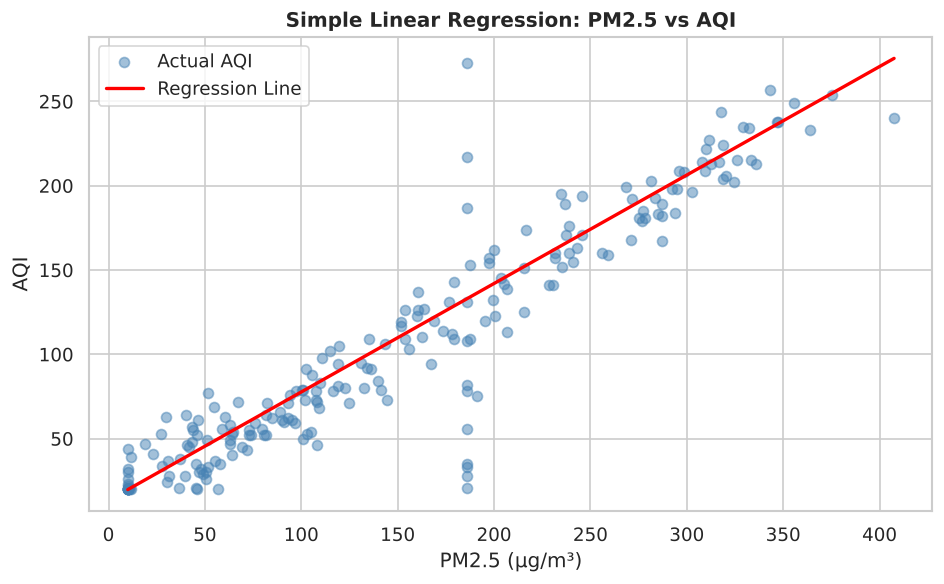

In [14]:
# SLR — Scatter + regression line
x_range = np.linspace(X_test['PM2.5'].min(), X_test['PM2.5'].max(), 200).reshape(-1,1)
y_line  = slr.predict(x_range)

plt.figure(figsize=(8, 5))
plt.scatter(X_test['PM2.5'], y_test, alpha=0.5, color='steelblue', label='Actual AQI')
plt.plot(x_range, y_line, color='red', linewidth=2, label='Regression Line')
plt.xlabel('PM2.5 (µg/m³)'); plt.ylabel('AQI')
plt.title('Simple Linear Regression: PM2.5 vs AQI', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()


### 4.2 Multiple Linear Regression

In [15]:
# Multiple Linear Regression
mlr = LinearRegression()
mlr.fit(X_train_sc, y_train)
y_pred_mlr = mlr.predict(X_test_sc)

r2_mlr  = r2_score(y_test, y_pred_mlr)
mse_mlr = mean_squared_error(y_test, y_pred_mlr)

print("=" * 50)
print("   MULTIPLE LINEAR REGRESSION — COEFFICIENTS")
print("=" * 50)
coef_df = pd.DataFrame({
    'Feature': selected_features,
    'Coefficient': mlr.coef_
}).sort_values('Coefficient', ascending=False)
print(coef_df.to_string(index=False))
print(f"\n  Intercept : {mlr.intercept_:.4f}")
print(f"  R²        : {r2_mlr:.4f}")
print(f"  MSE       : {mse_mlr:.4f}")
print(f"  RMSE      : {np.sqrt(mse_mlr):.4f}")
print("=" * 50)


   MULTIPLE LINEAR REGRESSION — COEFFICIENTS
    Feature  Coefficient
      PM2.5    27.782745
       PM10    25.084216
        NO2     6.004816
 PM25_roll7     5.208528
         CO     4.352623
        SO2     3.209865
  AQI_roll3     2.385894
   AQI_lag1     1.201998
         O3     1.192502
   Humidity    -1.116343
Temperature    -2.456513
   AQI_lag2    -2.776487

  Intercept : 135.6391
  R²        : 0.9378
  MSE       : 291.7394
  RMSE      : 17.0804


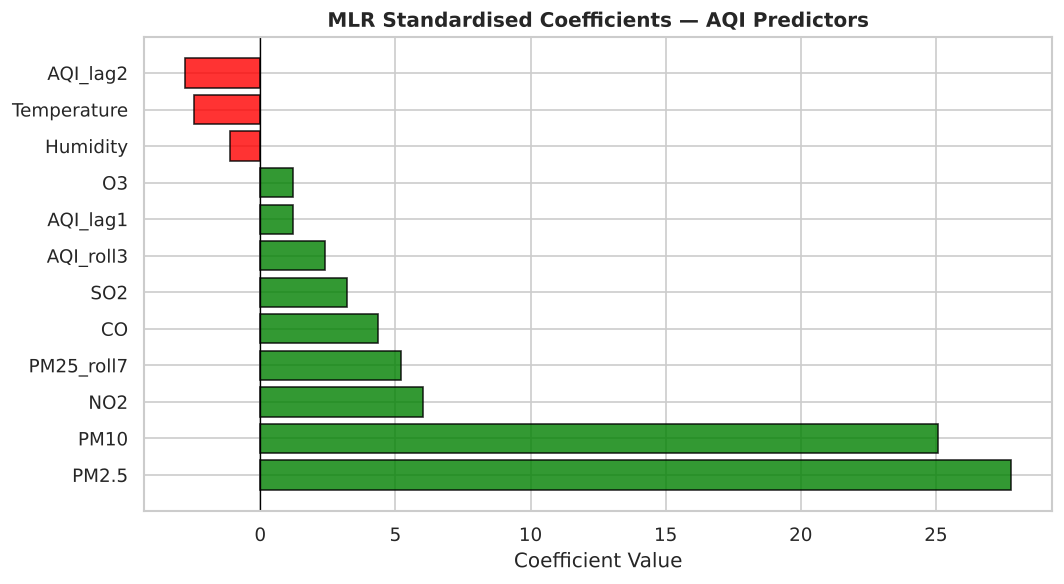


📌 Interpretation of coefficients (standardised):
  Positive coefficient → feature increases AQI
  Negative coefficient → feature decreases AQI
  Larger |value| → stronger influence


In [16]:
# Coefficient plot
plt.figure(figsize=(9, 5))
colors = ['green' if c > 0 else 'red' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='black', alpha=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('MLR Standardised Coefficients — AQI Predictors', fontweight='bold')
plt.xlabel('Coefficient Value')
plt.tight_layout(); plt.show()

print("\n📌 Interpretation of coefficients (standardised):")
print("  Positive coefficient → feature increases AQI")
print("  Negative coefficient → feature decreases AQI")
print("  Larger |value| → stronger influence")


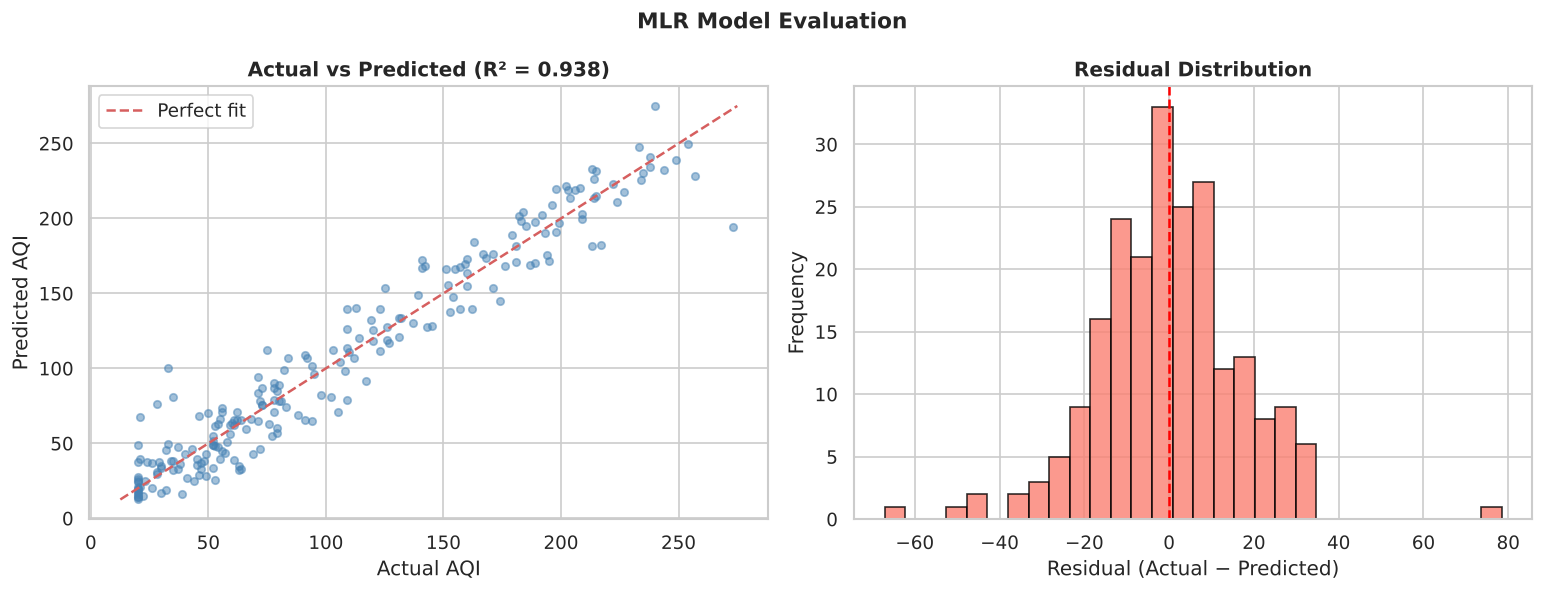


📊 Regression Model Comparison:
Model                                R²          MSE       RMSE
--------------------------------------------------------------
Simple LR (PM2.5 only)           0.8729       595.89      24.41
Multiple LR (all features)       0.9378       291.74      17.08


In [17]:
# Actual vs Predicted + Residuals
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred_mlr, alpha=0.5, color='steelblue', s=20)
lims = [min(y_test.min(), y_pred_mlr.min()), max(y_test.max(), y_pred_mlr.max())]
axes[0].plot(lims, lims, 'r--', linewidth=1.5, label='Perfect fit')
axes[0].set_xlabel('Actual AQI'); axes[0].set_ylabel('Predicted AQI')
axes[0].set_title(f'Actual vs Predicted (R² = {r2_mlr:.3f})', fontweight='bold')
axes[0].legend()

# Residuals
residuals = y_test - y_pred_mlr
axes[1].hist(residuals, bins=30, color='salmon', edgecolor='black', alpha=0.8)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Residual Distribution', fontweight='bold')
axes[1].set_xlabel('Residual (Actual − Predicted)')
axes[1].set_ylabel('Frequency')

plt.suptitle('MLR Model Evaluation', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

# Summary table
print("\n📊 Regression Model Comparison:")
print(f"{'Model':<30} {'R²':>8} {'MSE':>12} {'RMSE':>10}")
print("-"*62)
print(f"{'Simple LR (PM2.5 only)':<30} {r2_slr:>8.4f} {mse_slr:>12.2f} {np.sqrt(mse_slr):>10.2f}")
print(f"{'Multiple LR (all features)':<30} {r2_mlr:>8.4f} {mse_mlr:>12.2f} {np.sqrt(mse_mlr):>10.2f}")


---
## 5. Classification Analysis — High Pollution Prediction

**Definition:**  
$$\text{High Pollution} = \begin{cases} 1 & \text{if AQI} \geq 201 \\ 0 & \text{otherwise} \end{cases}$$


Class distribution:
  Class 0 (Low/Moderate): 854 (78.5%)
  Class 1 (High):         234 (21.5%)


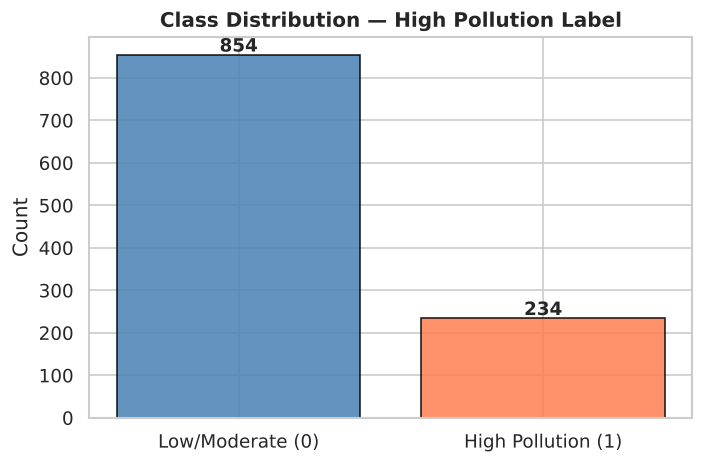

In [18]:
# Create binary target
df_clean['High_Pollution'] = (df_clean['AQI'] >= 201).astype(int)

print("Class distribution:")
vc = df_clean['High_Pollution'].value_counts()
print(f"  Class 0 (Low/Moderate): {vc[0]} ({vc[0]/len(df_clean)*100:.1f}%)")
print(f"  Class 1 (High):         {vc[1]} ({vc[1]/len(df_clean)*100:.1f}%)")

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Low/Moderate (0)', 'High Pollution (1)'], [vc[0], vc[1]],
       color=['steelblue', 'coral'], edgecolor='black', alpha=0.85)
ax.set_title('Class Distribution — High Pollution Label', fontweight='bold')
ax.set_ylabel('Count')
for i, v in enumerate([vc[0], vc[1]]):
    ax.text(i, v + 8, str(v), ha='center', fontweight='bold')
plt.tight_layout(); plt.show()


In [19]:
# Classification features & split
clf_features = ['PM2.5','PM10','NO2','SO2','CO','O3',
                'Temperature','Humidity','Wind_Speed',
                'AQI_lag1','AQI_lag2','AQI_roll3']

X_clf = df_clean[clf_features]
y_clf = df_clean['High_Pollution']

# Time-ordered split: train on the earlier 80% of days, test on the most recent 20%,
# so the model is never evaluated on days that come before its training data.
X_tr, X_te, y_tr, y_te = train_test_split(
    X_clf, y_clf, test_size=0.2, shuffle=False
)
sc_clf = StandardScaler()
X_tr_sc = sc_clf.fit_transform(X_tr)
X_te_sc  = sc_clf.transform(X_te)

print(f"Train: {X_tr.shape[0]} | Test: {X_te.shape[0]}")
print(f"Train class balance: {y_tr.value_counts().to_dict()}")


Train: 870 | Test: 218
Train class balance: {0: 664, 1: 206}


### 5.1 Logistic Regression

      LOGISTIC REGRESSION RESULTS
              precision    recall  f1-score   support

     Low (0)       0.98      0.97      0.98       190
    High (1)       0.83      0.89      0.86        28

    accuracy                           0.96       218
   macro avg       0.91      0.93      0.92       218
weighted avg       0.96      0.96      0.96       218



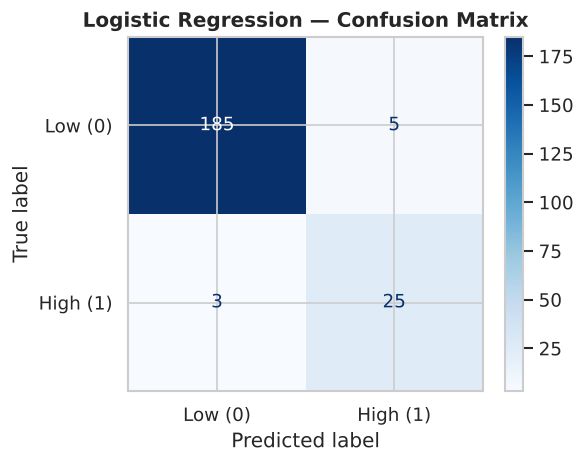

In [20]:
lr_clf = LogisticRegression(max_iter=1000, random_state=42)
lr_clf.fit(X_tr_sc, y_tr)
y_pred_lr = lr_clf.predict(X_te_sc)

print("=" * 45)
print("      LOGISTIC REGRESSION RESULTS")
print("=" * 45)
print(classification_report(y_te, y_pred_lr, target_names=['Low (0)', 'High (1)']))

# Confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred_lr,
    display_labels=['Low (0)', 'High (1)'],
    cmap='Blues', ax=ax)
ax.set_title('Logistic Regression — Confusion Matrix', fontweight='bold')
plt.tight_layout(); plt.show()


### 5.2 Decision Tree

        DECISION TREE RESULTS
              precision    recall  f1-score   support

     Low (0)       0.98      0.99      0.99       190
    High (1)       0.93      0.89      0.91        28

    accuracy                           0.98       218
   macro avg       0.96      0.94      0.95       218
weighted avg       0.98      0.98      0.98       218



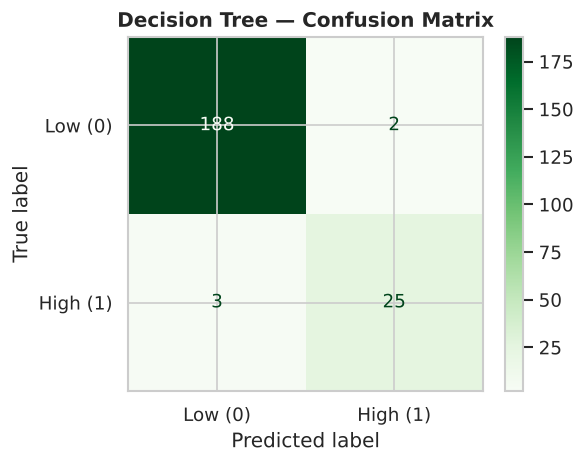

In [21]:
dt_clf = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_clf.fit(X_tr, y_tr)
y_pred_dt = dt_clf.predict(X_te)

print("=" * 45)
print("        DECISION TREE RESULTS")
print("=" * 45)
print(classification_report(y_te, y_pred_dt, target_names=['Low (0)', 'High (1)']))

# Confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred_dt,
    display_labels=['Low (0)', 'High (1)'],
    cmap='Greens', ax=ax)
ax.set_title('Decision Tree — Confusion Matrix', fontweight='bold')
plt.tight_layout(); plt.show()


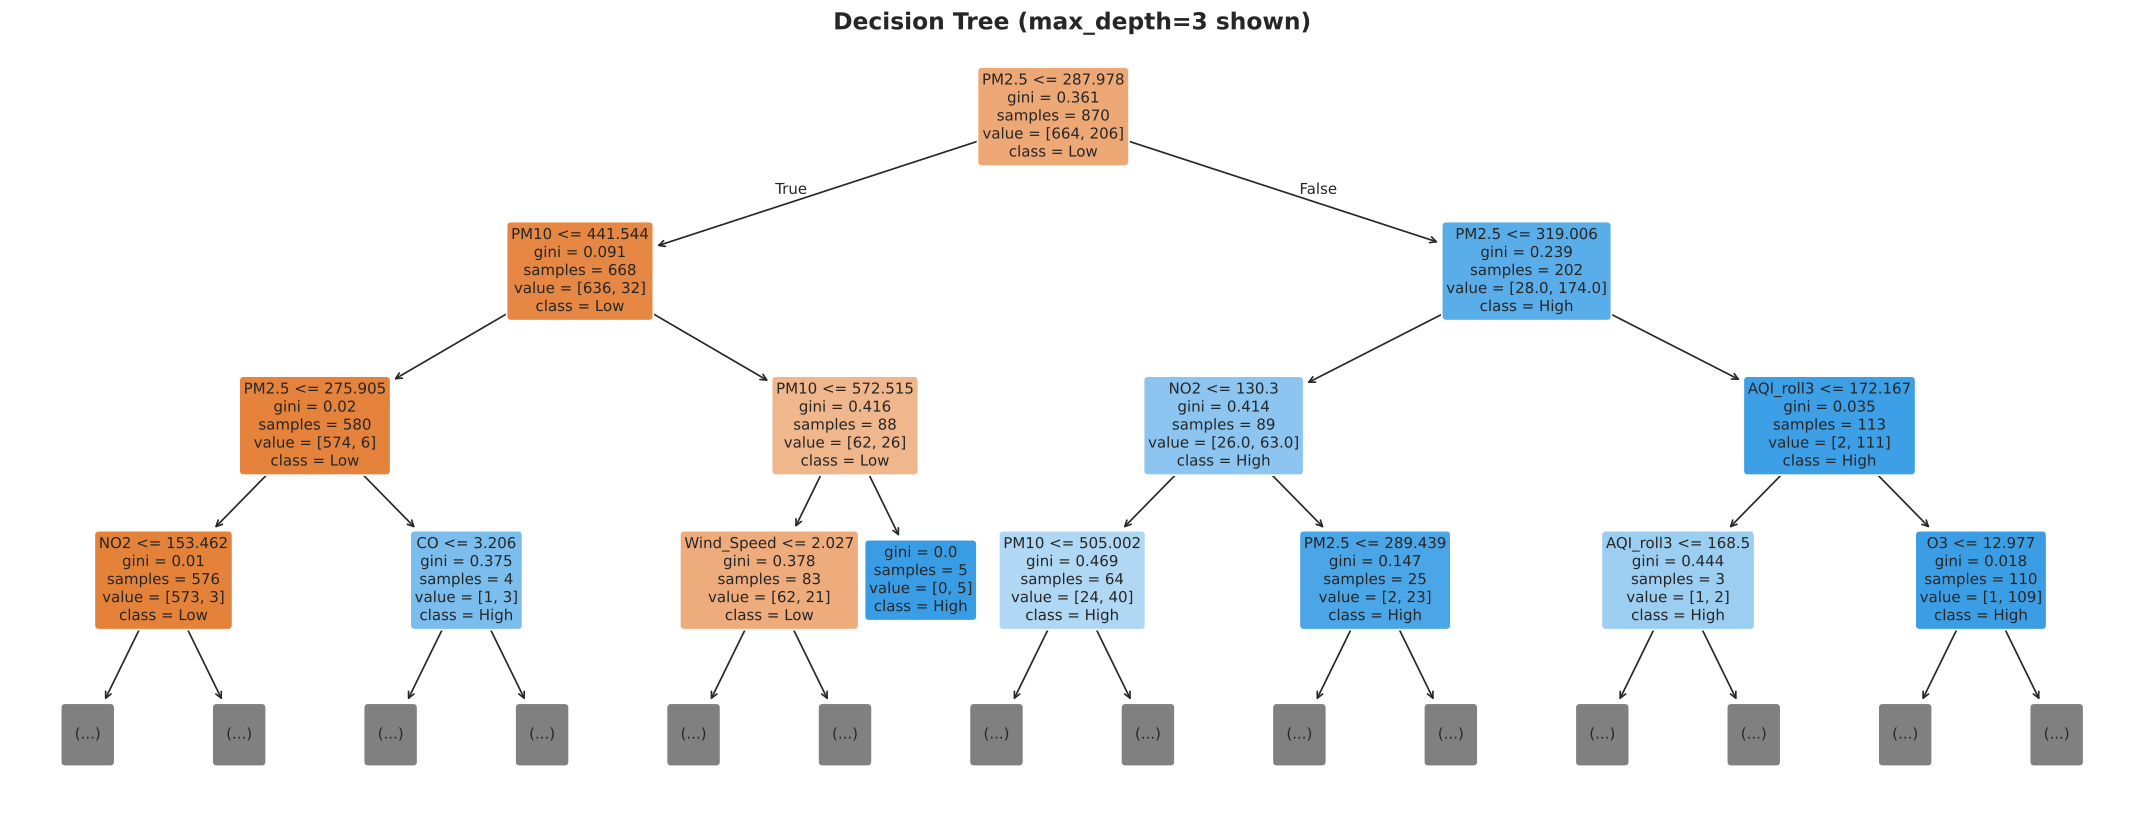

In [22]:
# Visualise Decision Tree (top 3 levels)
plt.figure(figsize=(18, 7))
plot_tree(dt_clf, feature_names=clf_features,
          class_names=['Low', 'High'], filled=True,
          rounded=True, max_depth=3, fontsize=9)
plt.title('Decision Tree (max_depth=3 shown)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


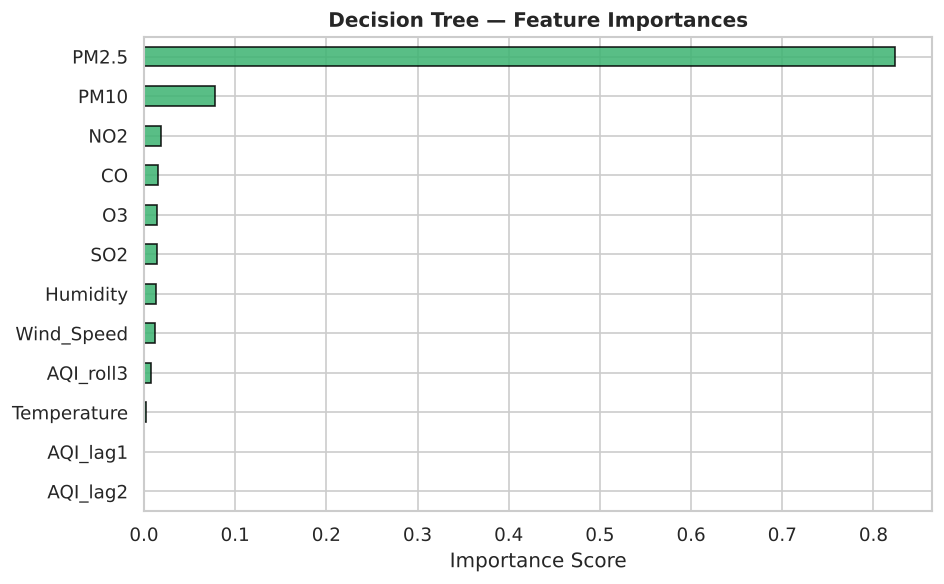

In [23]:
# Feature importance — Decision Tree
fi_dt = pd.Series(dt_clf.feature_importances_, index=clf_features).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
fi_dt.plot(kind='barh', color='mediumseagreen', edgecolor='black', alpha=0.85)
plt.title('Decision Tree — Feature Importances', fontweight='bold')
plt.xlabel('Importance Score')
plt.tight_layout(); plt.show()


### 5.3 Random Forest

       RANDOM FOREST RESULTS
              precision    recall  f1-score   support

     Low (0)       0.99      0.98      0.99       190
    High (1)       0.90      0.93      0.91        28

    accuracy                           0.98       218
   macro avg       0.94      0.96      0.95       218
weighted avg       0.98      0.98      0.98       218



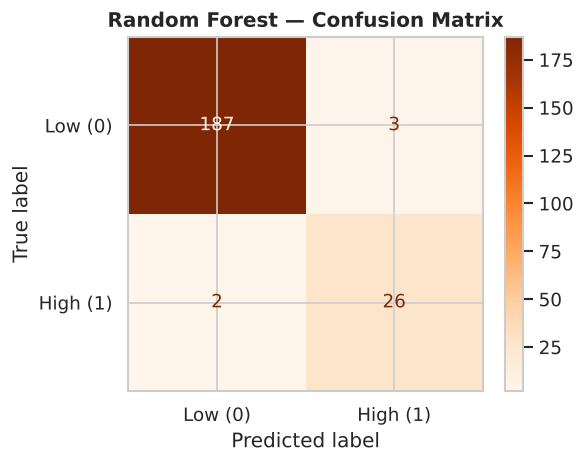

In [24]:
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_clf.fit(X_tr, y_tr)
y_pred_rf = rf_clf.predict(X_te)

print("=" * 45)
print("       RANDOM FOREST RESULTS")
print("=" * 45)
print(classification_report(y_te, y_pred_rf, target_names=['Low (0)', 'High (1)']))

# Confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred_rf,
    display_labels=['Low (0)', 'High (1)'],
    cmap='Oranges', ax=ax)
ax.set_title('Random Forest — Confusion Matrix', fontweight='bold')
plt.tight_layout(); plt.show()


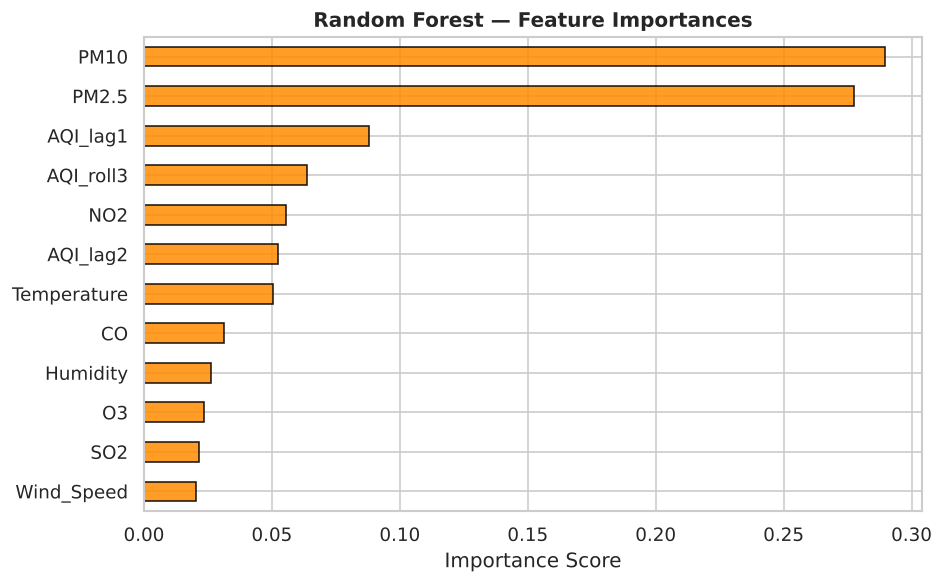

In [25]:
# Feature importance — Random Forest
fi_rf = pd.Series(rf_clf.feature_importances_, index=clf_features).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
fi_rf.plot(kind='barh', color='darkorange', edgecolor='black', alpha=0.85)
plt.title('Random Forest — Feature Importances', fontweight='bold')
plt.xlabel('Importance Score')
plt.tight_layout(); plt.show()


### 5.4 Model Comparison

In [26]:
# Compute metrics for all three
def metrics(y_true, y_pred):
    return {
        'Accuracy' : accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall'   : recall_score(y_true, y_pred),
        'F1-Score' : f1_score(y_true, y_pred),
    }

results = pd.DataFrame({
    'Logistic Regression': metrics(y_te, y_pred_lr),
    'Decision Tree'      : metrics(y_te, y_pred_dt),
    'Random Forest'      : metrics(y_te, y_pred_rf),
}).T.round(4)

print("=" * 60)
print("           MODEL COMPARISON — CLASSIFICATION")
print("=" * 60)
print(results.to_string())
print("=" * 60)


           MODEL COMPARISON — CLASSIFICATION
                     Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.9633     0.8333  0.8929    0.8621
Decision Tree          0.9771     0.9259  0.8929    0.9091
Random Forest          0.9771     0.8966  0.9286    0.9123


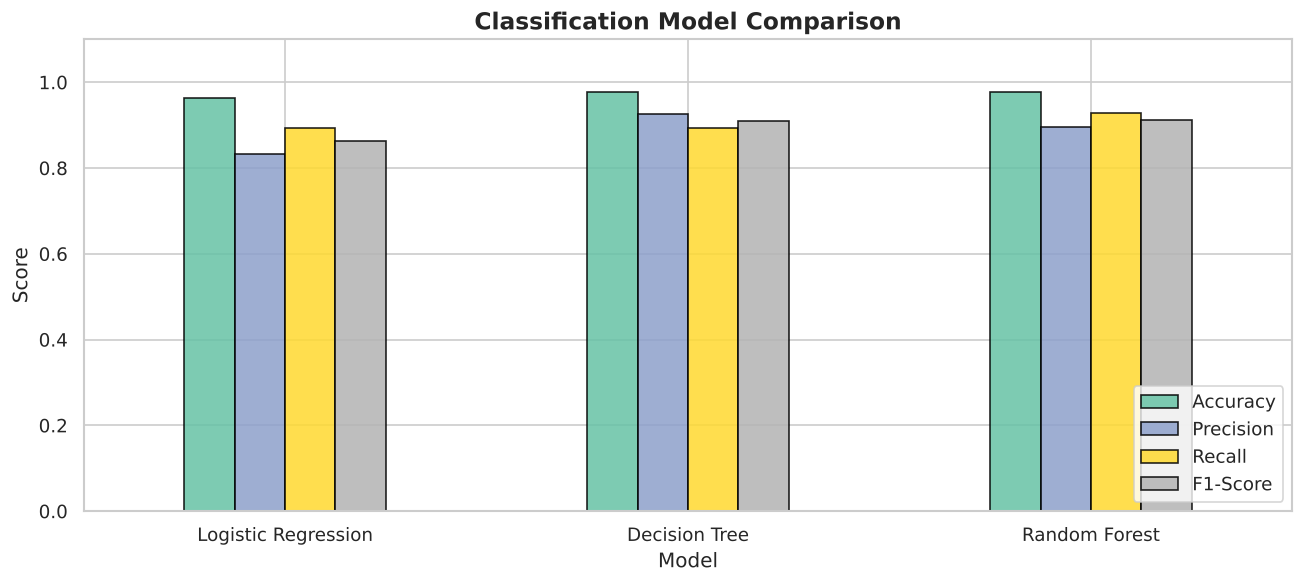


🏆 Best model by F1-Score: Random Forest (0.9123)


In [27]:
# Bar chart comparison
results.plot(kind='bar', figsize=(11, 5), colormap='Set2', edgecolor='black', alpha=0.85)
plt.title('Classification Model Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

# Winner
best_model = results['F1-Score'].idxmax()
print(f"\n🏆 Best model by F1-Score: {best_model} ({results.loc[best_model,'F1-Score']:.4f})")


---
## 6. Clustering Analysis — K-Means

### 6.1 Feature Selection & Normalisation


In [28]:
# Select features for clustering: AQI + lags + rolling averages
cluster_features = ['AQI', 'AQI_lag1', 'AQI_roll3', 'PM2.5', 'PM25_roll7']
df_cluster = df_clean[cluster_features].dropna().copy()

sc_km = StandardScaler()
X_km  = sc_km.fit_transform(df_cluster)

print(f"Clustering dataset shape: {df_cluster.shape}")
print(f"Features used: {cluster_features}")


Clustering dataset shape: (1088, 5)
Features used: ['AQI', 'AQI_lag1', 'AQI_roll3', 'PM2.5', 'PM25_roll7']


### 6.2 Elbow Method — Optimal k

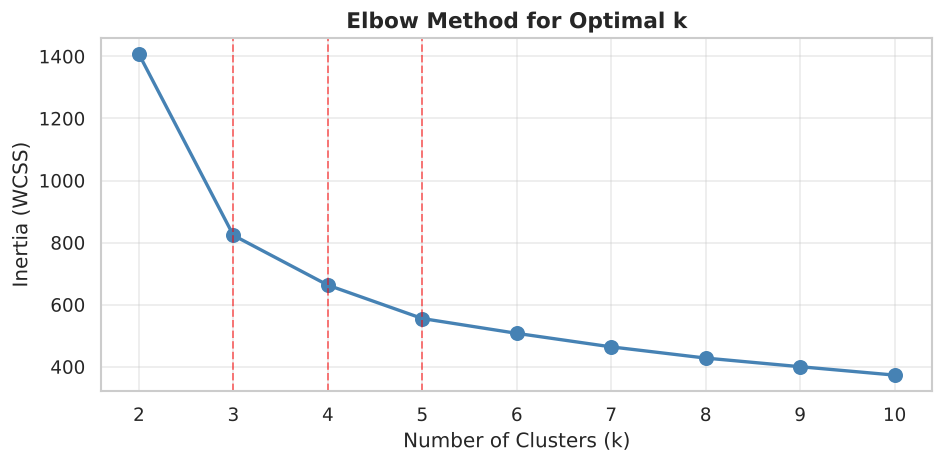


Inertia values:
  k=2: 1,407.3
  k=3: 823.4
  k=4: 662.9
  k=5: 555.4
  k=6: 507.6
  k=7: 464.0
  k=8: 427.9
  k=9: 400.1
  k=10: 373.0


In [29]:
# Elbow method: k = 2 to 10
inertias = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_km)
    inertias[k] = km.inertia_

plt.figure(figsize=(8, 4))
plt.plot(list(inertias.keys()), list(inertias.values()), marker='o',
         color='steelblue', linewidth=2, markersize=8)
for k in [3, 4, 5]:
    plt.axvline(k, color='red', linestyle='--', alpha=0.5, linewidth=1.2)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method for Optimal k', fontsize=13, fontweight='bold')
plt.xticks(range(2, 11))
plt.grid(True, alpha=0.4)
plt.tight_layout(); plt.show()

print("\nInertia values:")
for k, v in inertias.items():
    print(f"  k={k}: {v:,.1f}")


### 6.3 K-Means with k = 3, 4, 5

In [30]:
# Fit K-Means for k = 3, 4, 5
km_models = {}
for k in [3, 4, 5]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_km)
    km_models[k] = km
    df_cluster[f'Cluster_k{k}'] = km.labels_
    print(f"k={k} → Inertia: {km.inertia_:,.1f} | Cluster sizes: {dict(pd.Series(km.labels_).value_counts().sort_index())}")


k=3 → Inertia: 823.4 | Cluster sizes: {0: np.int64(424), 1: np.int64(388), 2: np.int64(276)}
k=4 → Inertia: 662.9 | Cluster sizes: {0: np.int64(341), 1: np.int64(206), 2: np.int64(243), 3: np.int64(298)}
k=5 → Inertia: 555.4 | Cluster sizes: {0: np.int64(198), 1: np.int64(205), 2: np.int64(188), 3: np.int64(241), 4: np.int64(256)}


Explained variance (PC1 + PC2): 97.2%


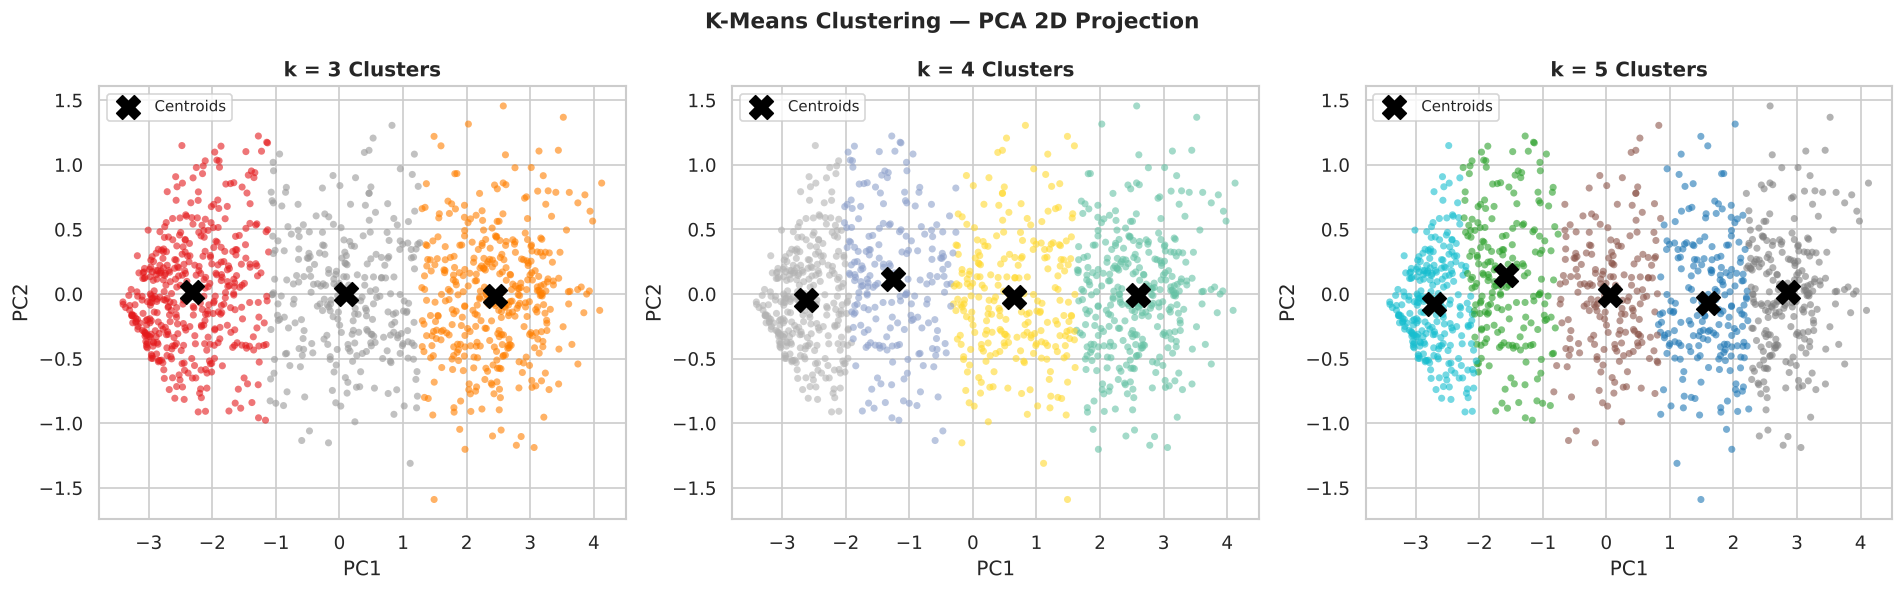

In [31]:
# PCA 2D projection for visualisation
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_km)
print(f"Explained variance (PC1 + PC2): {pca.explained_variance_ratio_.sum()*100:.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
palettes = {3: 'Set1', 4: 'Set2', 5: 'tab10'}
titles   = {3: 'k = 3 Clusters', 4: 'k = 4 Clusters', 5: 'k = 5 Clusters'}

for ax, k in zip(axes, [3, 4, 5]):
    labels = df_cluster[f'Cluster_k{k}'].values
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1],
                         c=labels, cmap=palettes[k],
                         alpha=0.6, s=18, edgecolors='none')
    # Mark centroids in PCA space
    centroids_pca = pca.transform(km_models[k].cluster_centers_)
    ax.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
               c='black', marker='X', s=200, zorder=5, label='Centroids')
    ax.set_title(titles[k], fontweight='bold')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(fontsize=9)

plt.suptitle('K-Means Clustering — PCA 2D Projection', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()



📊 Cluster Profiles (k=3):
             AQI  PM2.5  AQI_roll3  Size
Cluster 0   54.1   73.9       55.8   424
Cluster 2  133.5  187.0      133.0   276
Cluster 1  209.4  297.0      207.8   388


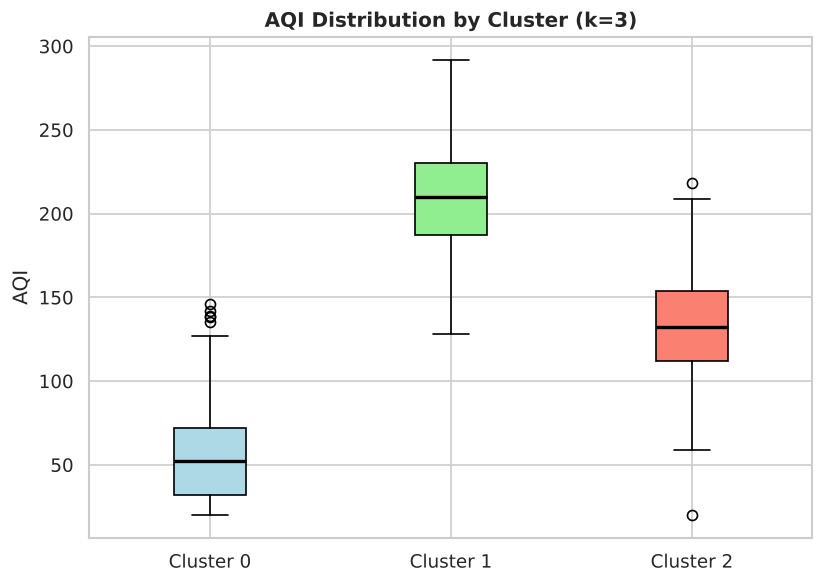

In [32]:
# Cluster profiles — k=3 (recommended by elbow)
optimal_k = 3
df_cluster['Cluster'] = df_cluster[f'Cluster_k{optimal_k}']

profile = df_cluster.groupby('Cluster')[['AQI', 'PM2.5', 'AQI_roll3']].mean().round(1)
profile['Size']   = df_cluster['Cluster'].value_counts().sort_index()
profile = profile.sort_values('AQI')
profile.index = [f'Cluster {i}' for i in profile.index]
print("\n📊 Cluster Profiles (k=3):")
print(profile.to_string())

# AQI boxplot by cluster
plt.figure(figsize=(7, 5))
groups = [df_cluster[df_cluster['Cluster'] == i]['AQI'].values for i in range(optimal_k)]
bp = plt.boxplot(groups,
                 tick_labels=[f'Cluster {i}' for i in range(optimal_k)],
                 patch_artist=True,
                 medianprops={'color':'black','linewidth':2})
colors_box = ['lightblue', 'lightgreen', 'salmon']
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
plt.title(f'AQI Distribution by Cluster (k={optimal_k})', fontweight='bold')
plt.ylabel('AQI')
plt.tight_layout(); plt.show()


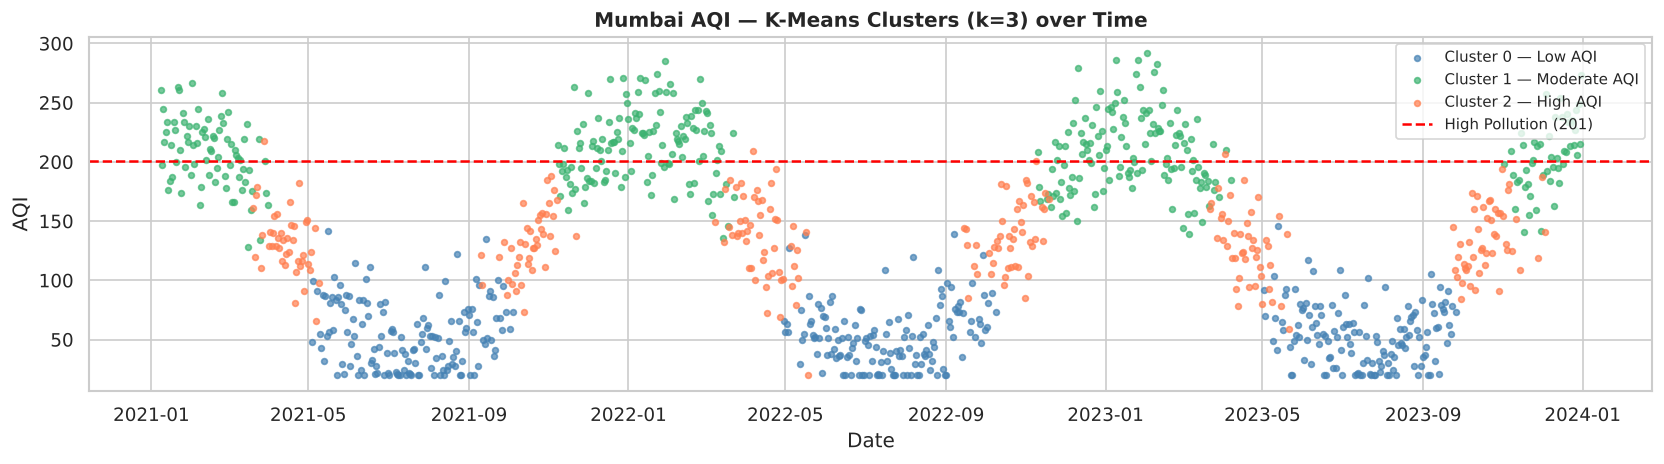

In [33]:
# AQI scatter plot with cluster colour (k=3)
df_cluster_plot = df_cluster.copy()
df_cluster_plot['Date'] = df_clean.loc[df_cluster.index, 'Date']

plt.figure(figsize=(14, 4))
colors_scatter = {0: 'steelblue', 1: 'mediumseagreen', 2: 'coral'}
labels_scatter = {0: 'Cluster 0 — Low AQI', 1: 'Cluster 1 — Moderate AQI', 2: 'Cluster 2 — High AQI'}

for c in sorted(df_cluster_plot['Cluster'].unique()):
    mask = df_cluster_plot['Cluster'] == c
    plt.scatter(df_cluster_plot.loc[mask, 'Date'],
                df_cluster_plot.loc[mask, 'AQI'],
                s=12, alpha=0.7, color=colors_scatter[c],
                label=labels_scatter.get(c, f'Cluster {c}'))

plt.axhline(201, color='red', linestyle='--', linewidth=1.5, label='High Pollution (201)')
plt.title('Mumbai AQI — K-Means Clusters (k=3) over Time', fontweight='bold')
plt.xlabel('Date'); plt.ylabel('AQI')
plt.legend(loc='upper right', fontsize=9)
plt.tight_layout(); plt.show()


In [34]:
from sklearn.pipeline import make_pipeline


---
## 8. Next-Day Forecast — Can we warn people a day ahead?

The models above use **same-day** pollutant readings, so they explain today's AQI rather than predict tomorrow's. For an early-warning system the question is different: using only what is known **today**, how well can we predict **tomorrow's** AQI?

Every model is compared against a **persistence baseline** ("tomorrow will be like today"), which is the standard benchmark for air-quality forecasting.


In [35]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

fc = df.sort_values('Date').reset_index(drop=True).copy()
for col in feature_cols:
    fc[col] = fc[col].fillna(fc[col].median())

# Features known at the end of day t
fc['AQI_today']  = fc['AQI']
fc['AQI_lag1']   = fc['AQI'].shift(1)
fc['AQI_roll7']  = fc['AQI'].rolling(7).mean()
doy = fc['Date'].dt.dayofyear
fc['season_sin'] = np.sin(2 * np.pi * doy / 365.25)   # smooth seasonal cycle
fc['season_cos'] = np.cos(2 * np.pi * doy / 365.25)

# Target: AQI on day t+1
fc['AQI_tomorrow'] = fc['AQI'].shift(-1)
fc = fc.dropna().reset_index(drop=True)

fc_features = feature_cols + ['AQI_today', 'AQI_lag1', 'AQI_roll7', 'season_sin', 'season_cos']
split = int(len(fc) * 0.8)
train, test = fc.iloc[:split], fc.iloc[split:]
print(f"Train: {train['Date'].min().date()} → {train['Date'].max().date()}  ({len(train)} days)")
print(f"Test : {test['Date'].min().date()} → {test['Date'].max().date()}  ({len(test)} days)")


Train: 2021-01-07 → 2023-05-26  (870 days)
Test : 2023-05-27 → 2023-12-30  (218 days)


In [36]:
def score(name, pred):
    return {'Model': name,
            'MAE':  mean_absolute_error(test['AQI_tomorrow'], pred),
            'RMSE': mean_squared_error(test['AQI_tomorrow'], pred) ** 0.5,
            'R²':   r2_score(test['AQI_tomorrow'], pred)}

lin_fc = make_pipeline(StandardScaler(), LinearRegression()).fit(train[fc_features], train['AQI_tomorrow'])
rf_fc  = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)
rf_fc.fit(train[fc_features], train['AQI_tomorrow'])

fc_results = pd.DataFrame([
    score('Persistence (tomorrow = today)', test['AQI_today']),
    score('Linear regression', lin_fc.predict(test[fc_features])),
    score('Random forest', rf_fc.predict(test[fc_features])),
]).set_index('Model').round(3)
print(fc_results.to_string())

gain = 1 - fc_results.loc['Linear regression', 'MAE'] / fc_results.loc['Persistence (tomorrow = today)', 'MAE']
print(f"\nLinear model cuts the average next-day error by {gain:.0%} versus persistence.")


                                   MAE    RMSE     R²
Model                                                
Persistence (tomorrow = today)  28.995  37.279  0.704
Linear regression               20.423  26.172  0.854
Random forest                   21.205  26.479  0.850

Linear model cuts the average next-day error by 30% versus persistence.


High-pollution days in test period : 28
  correctly warned the day before  : 19
  false alarms                     : 9


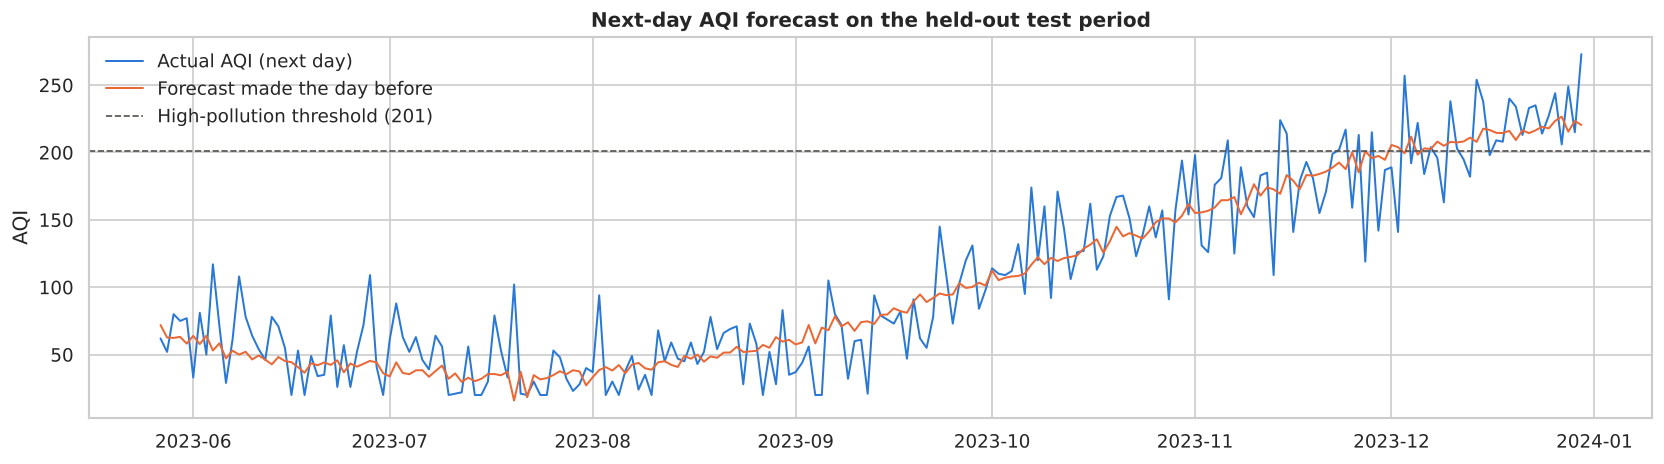

In [37]:
# Did the forecast catch tomorrow's high-pollution days (AQI >= 201)?
pred_tomorrow = lin_fc.predict(test[fc_features])
actual_high   = test['AQI_tomorrow'] >= 201
warned        = pred_tomorrow >= 201
print(f"High-pollution days in test period : {actual_high.sum()}")
print(f"  correctly warned the day before  : {(actual_high & warned).sum()}")
print(f"  false alarms                     : {(~actual_high & warned).sum()}")

plt.figure(figsize=(14, 4))
plt.plot(test['Date'], test['AQI_tomorrow'], color='#2a78d6', lw=1.2, label='Actual AQI (next day)')
plt.plot(test['Date'], pred_tomorrow, color='#eb6834', lw=1.2, label='Forecast made the day before')
plt.axhline(201, color='#52514e', ls='--', lw=1, label='High-pollution threshold (201)')
plt.title('Next-day AQI forecast on the held-out test period', fontweight='bold')
plt.ylabel('AQI'); plt.legend(frameon=False); plt.tight_layout(); plt.show()


---
## 9. Summary & Conclusions

### 9.1 Explaining today's AQI (regression, time-ordered test set)
| Model | R² | RMSE |
|---|---|---|
| Simple LR (PM2.5 → AQI) | 0.87 | 24.4 |
| Multiple LR (all features) | 0.94 | 17.1 |

- **PM2.5 and PM10** carry most of the signal; adding the other pollutants, weather and lagged AQI lowers the error by about 30%.

### 9.2 Flagging high-pollution days (AQI ≥ 201, time-ordered test set)
| Model | Accuracy | F1 (High) |
|---|---|---|
| Logistic Regression | 0.96 | 0.86 |
| Decision Tree | 0.98 | 0.91 |
| Random Forest | 0.98 | 0.91 |

- In the Random Forest, **PM10 and PM2.5** are the most important features, followed by the previous day's AQI.

### 9.3 Forecasting tomorrow's AQI
| Model | MAE | R² |
|---|---|---|
| Persistence (tomorrow = today) | 29.0 | 0.70 |
| Linear regression | 20.4 | 0.85 |
| Random forest | 21.2 | 0.85 |

- Using only information available today, a linear model cuts next-day error by **30%** against persistence and gave a day's warning for **19 of 28** high-pollution days in the test period (9 false alarms).

### 9.4 Pollution regimes (K-means, k = 3)
- Three regimes emerge: low (mean AQI 54), moderate (134) and high (209).
- The high regime falls almost entirely between **November and March**, matching Mumbai's winter pollution season; monsoon months are the cleanest.

### 9.5 Policy implications
1. **Early warning is feasible:** a simple next-day forecast already beats persistence and catches most high-pollution days, which is enough to trigger advance health advisories.
2. **Target particulates:** PM2.5 and PM10 dominate, pointing to vehicular emissions, construction dust and industry as the main levers.
3. **Seasonal controls:** stricter dust and emission controls from November to March would address the peak-pollution regime.
